In [1]:
using Statistics
using LinearAlgebra
using Plots
using DataFrames
using BSON: @save, @load
using ProgressMeter
using Printf
using DataStructures: OrderedDict
using IterTools
using Random
using Measures
using Base.Threads: @threads, nthreads, threadid, SpinLock
using JLD2

In [2]:
base_dir = @__DIR__
results_dir = joinpath(base_dir, "PRB_test_results")
isdir(results_dir) || mkdir(results_dir)

true

In [3]:
function log_range(base::Float64, start_power::Float64, end_power::Float64, length::Int)
    powers = range(start_power, stop=end_power, length=length)
    values = base .^ powers
    return values
end

function t_ranges_combs(t_ranges::Vector{Vector{Float64}})
    t_combinations_matrix = collect(IterTools.product(t_ranges...))
    t_combinations = [collect(t) for t in vec(t_combinations_matrix)]
    return t_combinations
end

t_ranges_combs (generic function with 1 method)

In [4]:
## Generate full set of slopes

N = 1000
map_to = (1,2)
qmin, qmax = 2, N

# 1. Threaded generation of all reduced rationals p/q in [0,1]
slopes = Float64[]
slope_lock = SpinLock()
slope_prog = Progress(qmax - qmin + 1; desc="Generating slopes")

@threads for q in qmin:qmax
    local_chunk = Float64[]
    sizehint!(local_chunk, q)
    for p in 1:q-1
        if gcd(p, q) == 1
            push!(local_chunk, p / q)
        end
    end
    lock(slope_lock)
    append!(slopes, local_chunk)
    next!(slope_prog)
    unlock(slope_lock)
end

push!(slopes, 0.0, 1.0)
sort!(slopes)
unique!(slopes)

println("Initially generated $(length(slopes)) slopes.")
# println("Last 10 slopes: ", slopes[end-10:end])

Generating slopes 100%|██████████████████████████████████| Time: 0:00:01


Initially generated 304193 slopes.


In [5]:
## Optionally rebalance slopes to fixed density

nbins = 100
nperbin = 1
edges = range(0.0, stop=1.0, length=nbins + 1)

bin_idx = clamp.(searchsortedfirst.(Ref(edges), slopes) .- 1, 1, nbins)
selected_unique = falses(length(slopes))
counts = zeros(Int, nbins)
for i in eachindex(slopes)
    b = bin_idx[i]
    if counts[b] < nperbin
        selected_unique[i] = true
        counts[b] += 1
    end
end

slopes = slopes[selected_unique]
println("Rebalanced to $(length(slopes)) unique slopes (nbins=$nbins, nperbin=$nperbin).")
# println("Last 10 slopes: ", slopes[end-10:end])

Rebalanced to 100 unique slopes (nbins=100, nperbin=1).


In [6]:
# ## Optionally filter for target slope or override to set custom slopes


# ## Optional: Filter for target slope
# target_slope = 2/(1 + sqrt(5)) # Set to a Float64 (e.g. 1/phi) to enable filtering, or nothing to disable
# slope_tol = 0.001

# if !isnothing(target_slope)
#     filter!(s -> abs(s - target_slope) <= slope_tol, slopes)
#     println("Filtered to $(length(slopes)) slopes within tolerance $slope_tol of target $target_slope.")
#     if isempty(slopes)
#         @warn "No slopes remained after filtering for target $target_slope with tolerance $slope_tol."
#     end
# end

## Overwrite to define literal slope
slopes = [0.6180048661800487]
# slopes = [target_slope]


1-element Vector{Float64}:
 0.6180048661800487

In [7]:
function cut_and_project_sequence(N::Int, slope::Float64; phason::Float64=0.0, map_to::Tuple{Int,Int}=(1,2))
    @assert N >= 1 "N must be >= 1"
    # @assert 0.0 < slope < 1.0 "slope expected in (0,1) for standard Sturmian words"
    phason = phason - floor(phason) # wrap into [0,1)
    seq = Vector{Int}(undef, N)
    frac = phason
    for n in 1:N
        frac += slope
        if frac >= 1.0
            frac -= 1.0
            # crossing an integer -> difference = 1
            seq[n] = map_to[1]   # "A"
        else
            seq[n] = map_to[2]   # "B"
        end
    end
    return seq
end

cut_and_project_sequence (generic function with 1 method)

In [8]:
phason_angle_range = [0.0] #collect(0.0:0.01:1.0)
n_slopes = length(slopes)
n_phason = length(phason_angle_range)
slot_count = n_slopes * n_phason

seqs = Vector{Vector{Int}}(undef, slot_count)
phis = Vector{Float64}(undef, slot_count)
phasons = Vector{Float64}(undef, slot_count)

seq_lock = SpinLock()
seq_prog = Progress(n_phason; desc="Cut-and-project")

@threads for ip in 1:n_phason
    phason = phason_angle_range[ip]
    base = (ip - 1) * n_slopes
    for is in 1:n_slopes
        idx = base + is
        phi = slopes[is]
        seqs[idx] = cut_and_project_sequence(N, phi; phason=phason, map_to=map_to)
        phis[idx] = phi
        phasons[idx] = phason
    end
    lock(seq_lock); next!(seq_prog); unlock(seq_lock)
end
println("Generated $(length(phis)) sequences across $(length(phason_angle_range)) phasons.")
println("Sample Example Sequence (phi=$(phis[1]), phason=$(phasons[1])): ", seqs[1][1:50])


Generated 1 sequences across 1 phasons.
Sample Example Sequence (phi=0.6180048661800487, phason=0.0): [2, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 2, 1, 2]


In [9]:
function create_bdg_hamiltonian(
    N::Int, 
    t_n::Vector{Float64}, 
    mu::Float64, 
    Delta::Float64, 
    sequence::Vector{Int}
)::Matrix{ComplexF64}
    H0 = zeros(ComplexF64, N, N)
    for i in 1:N
        H0[i, i] = -mu
    end
    for i in 1:N-1
        hopping_index = sequence[i]
        hopping_term = t_n[hopping_index]
        H0[i, i+1] = -hopping_term
        H0[i+1, i] = -hopping_term
    end

    Delta_matrix = zeros(ComplexF64, N, N)
    for i in 1:N-1
        Delta_matrix[i, i+1] = Delta
        Delta_matrix[i+1, i] = -Delta
    end

    BdG = zeros(ComplexF64, 2N, 2N)
    BdG[1:N, 1:N] = H0
    BdG[N+1:end, N+1:end] = -conj(H0)
    BdG[1:N, N+1:end] = Delta_matrix
    BdG[N+1:end, 1:N] = Delta_matrix'
    return BdG
end

create_bdg_hamiltonian (generic function with 1 method)

\begin{equation}
    H_{\text{Kitaev}} = \frac{i}{2} \sum_{j=1}^{L} \big( - \mu \gamma_{2j-1} \gamma_{2j} + (t_j + \Delta) \gamma_{2j} \gamma_{2j+1} + (\Delta -  t_j) \gamma_{2j-1} \gamma_{2j+2} \big) .
\end{equation}

Let $\tau_j = \Delta + t_j$ and $\nu_j = \Delta - t_j$

$t_j \in {t_0, t_1}$ where 
\begin{equation}
   t_j = t_0 + (t_1 - t_0)\left(\lfloor(j+1)\gamma+\phi\rfloor - \lfloor j\gamma+\phi\rfloor\right)
\end{equation}
defines a quasiperiodic sequence (e.g. $\phi=1/\varphi$ gives the Fibonacci word where $\varphi = (1+\sqrt(5))/2$).

In [10]:
N = 90
t_n = [1.0, 0.5]
rho = t_n[2] / t_n[1]
mu = 0.1
Delta = 0.3
sequence = seqs[1]

bdg_matrix = create_bdg_hamiltonian(N, t_n, mu, Delta, sequence)
println("Created BdG Hamiltonian of size $(size(bdg_matrix)).")

Created BdG Hamiltonian of size (180, 180).


In [11]:
function effective_coupling(e_L::Float64, e_R::Float64, e_max::Float64)
    return (e_L * e_R) / e_max
end

effective_coupling (generic function with 1 method)

Coupling over A- and B-dimers is 



In [12]:
function GF_A_Dimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_A = Delta + t_n[1]
    nu_A = Delta - t_n[1]
    Gamma_A = (mu^2 + tau_A * nu_A) / tau_A
    return Gamma_A
end

function GF_B_Dimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_B = Delta + t_n[2]
    nu_B = Delta - t_n[2]
    Gamma_B = (mu^2 + tau_B * nu_B) / tau_B
    return Gamma_B
end

function TM_A_Dimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_A = Delta + t_n[1]
    del_E = mu^2 / tau_A
    return del_E
end

function TM_B_Dimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_B = Delta + t_n[2]
    del_E = mu^2 / tau_B
    return del_E
end

function GF_AA_Trimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_A = Delta + t_n[1]
    nu_A = Delta - t_n[1]
    Gamma_AA = mu * (mu^2 + 2 * tau_A * nu_A) / tau_A^2
    return Gamma_AA
end

function GF_AB_Trimer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
)
    tau_A = Delta + t_n[1]
    nu_A = Delta - t_n[1]
    tau_B = Delta + t_n[2]
    nu_B = Delta - t_n[2]
    Gamma_AB = mu * mu^2 * (tau_A * nu_A + tau_B * nu_B) / (tau_A * tau_B)
    return Gamma_AB
end

GF_AB_Trimer (generic function with 1 method)

In [13]:
mu_range = 0.01:0.01:2.0
Delta_range = 0.01:0.01:1.0
t1_range = collect(range(1.0, 1.0, 1))
t2_range = collect(range(0.0, 0.1, 101))
t_n_range = Iterators.product(t1_range, t2_range)
param_combos = Iterators.product(mu_range, Delta_range, t_n_range)
total_combos = length(mu_range) * length(Delta_range) * length(t1_range) * length(t2_range)
println("Total parameter combinations: $total_combos")

Total parameter combinations: 2020000


In [14]:
coupling_results = Dict{String, Any}(
    "mu" => Float64[],
    "Delta" => Float64[],
    "t_1" => Float64[],
    "t_2" => Float64[],
    "rho" => Float64[],
    "Gamma_A" => Float64[],
    "Gamma_B" => Float64[],
    "del_E_A" => Float64[],
    "del_E_B" => Float64[],
    "Gamma_AA" => Float64[],
    "Gamma_AB" => Float64[],
    "min_energy" => Float64[],
    "min_energy_type" => String[],
)

for (mu, Delta, (t1, t2)) in param_combos
    t_n = [t1, t2]
    # println(typeof(t_n))
    Gamma_A = GF_A_Dimer(mu, Delta, t_n)
    Gamma_B = GF_B_Dimer(mu, Delta, t_n)
    del_E_A = TM_A_Dimer(mu, Delta, t_n)
    del_E_B = TM_B_Dimer(mu, Delta, t_n)
    Gamma_AA = GF_AA_Trimer(mu, Delta, t_n)
    Gamma_AB = GF_AB_Trimer(mu, Delta, t_n)

    min_energy = minimum([Gamma_A, Gamma_B, del_E_A, del_E_B, Gamma_AA, Gamma_AB])
    energy_types = ["Gamma_A", "Gamma_B", "del_E_A", "del_E_B", "Gamma_AA", "Gamma_AB"]
    min_energy_type = energy_types[argmin([Gamma_A, Gamma_B, del_E_A, del_E_B, Gamma_AA, Gamma_AB])]
    push!(coupling_results["min_energy"], min_energy)
    push!(coupling_results["min_energy_type"], min_energy_type)

    push!(coupling_results["mu"], mu)
    push!(coupling_results["Delta"], Delta)
    push!(coupling_results["t_1"], t1)
    push!(coupling_results["t_2"], t2)
    push!(coupling_results["rho"], t2 / t1)

    push!(coupling_results["Gamma_A"], Gamma_A)
    push!(coupling_results["Gamma_B"], Gamma_B)
    push!(coupling_results["del_E_A"], del_E_A)
    push!(coupling_results["del_E_B"], del_E_B)
    push!(coupling_results["Gamma_AA"], Gamma_AA)
    push!(coupling_results["Gamma_AB"], Gamma_AB)

end

In [24]:
function coupling_mask(
    coupling_results::Dict{String, Any};
    fixed_params...
)
    n = length(first(values(coupling_results)))
    mask = trues(n)

    for (param, value) in pairs(fixed_params)
        key = String(param)
        haskey(coupling_results, key) || error("Unknown parameter: $key")
        mask .&= isapprox.(coupling_results[key], value; atol=1e-8, rtol=0.0)
    end

    return mask
end

function plt_coupling_energy_1d(
    coupling_results::Dict{String, Any},
    x_var::String,
    y_var::String;
    fixed_params...
)
    mask = coupling_mask(coupling_results; fixed_params...)

    x_data = coupling_results[x_var][mask]
    y_data = coupling_results[y_var][mask]

    isempty(x_data) && error("No data matched the requested fixed parameters.")

    order = sortperm(x_data)
    plot(
        x_data[order],
        y_data[order];
        xlabel=x_var,
        ylabel=y_var,
        title="$y_var vs $x_var",
        legend=false
    )
end

function plt_coupling_energy_2d(
    coupling_results::Dict{String, Any},
    x_var::String,
    y_var::String,
    z_var::String;
    fixed_params...
)
    mask = coupling_mask(coupling_results; fixed_params...)

    x_data = coupling_results[x_var][mask]
    y_data = coupling_results[y_var][mask]
    z_data = coupling_results[z_var][mask]

    isempty(x_data) && error("No data matched the requested fixed parameters.")

    x_vals = sort(unique(x_data))
    y_vals = sort(unique(y_data))
    z_grid = fill(NaN, length(y_vals), length(x_vals))

    x_index = Dict(x => i for (i, x) in enumerate(x_vals))
    y_index = Dict(y => i for (i, y) in enumerate(y_vals))

    for (x, y, z) in zip(x_data, y_data, z_data)
        z_grid[y_index[y], x_index[x]] = z
    end

    heatmap(
        x_vals,
        y_vals,
        z_grid;
        xlabel=x_var,
        ylabel=y_var,
        colorbar_title=z_var,
        title="$z_var vs $x_var and $y_var"
    )
end

plt_coupling_energy_2d (generic function with 2 methods)

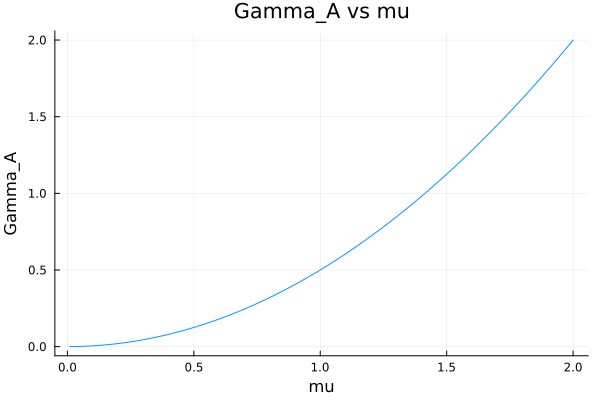

In [21]:
plt_coupling_energy_1d(
    coupling_results, 
    "mu", 
    "Gamma_A"; 
    t_1=1.0, 
    t_2=0.1, 
    Delta=1.0
)

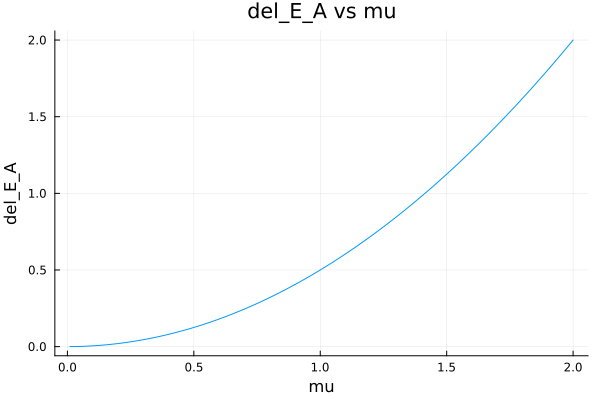

In [22]:
plt_coupling_energy_1d(
    coupling_results, 
    "mu", 
    "del_E_A"; 
    t_1=1.0, 
    t_2=0.1, 
    Delta=1.0
)

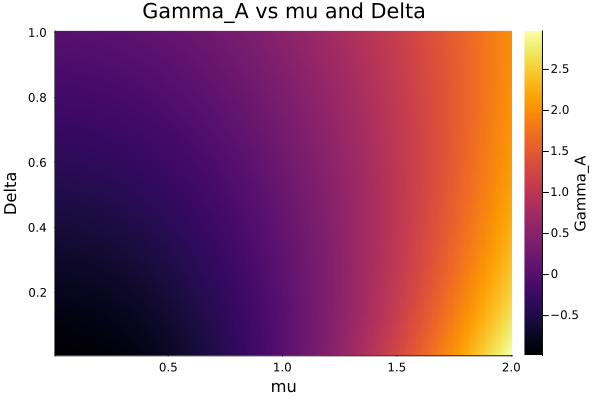

In [25]:
plt_coupling_energy_2d(
    coupling_results, 
    "mu", 
    "Delta", 
    "Gamma_A"; 
    t_1=1.0, 
    t_2=0.1
)

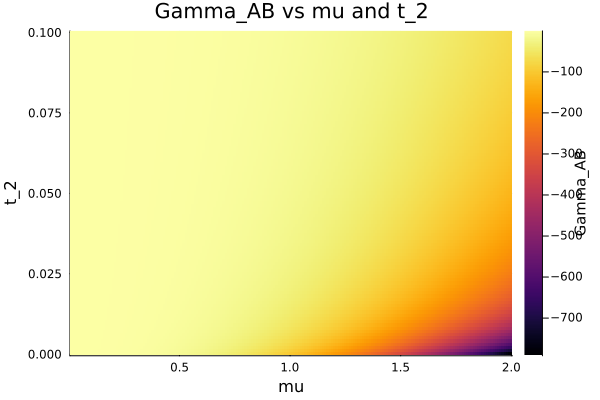

In [26]:
plt_coupling_energy_2d(
    coupling_results, 
    "mu", 
    "t_2", 
    "Gamma_AB"; 
    t_1=1.0, 
    Delta=0.01
)

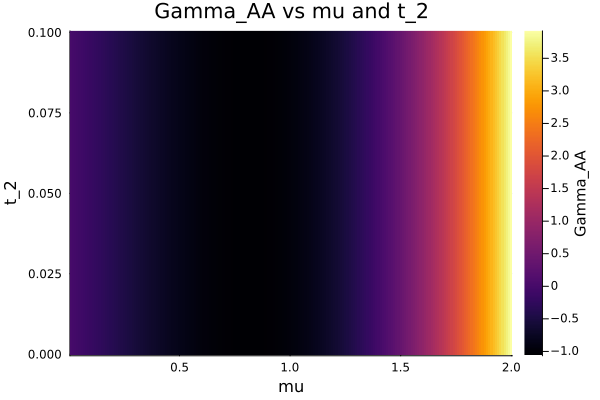

In [27]:
plt_coupling_energy_2d(
    coupling_results, 
    "mu", 
    "t_2", 
    "Gamma_AA"; 
    t_1=1.0, 
    Delta=0.01
)

## Transfer Matrix

$$H_{\text{Kitaev}} = \frac{i}{2} \sum_{j=1}^{L} \big( - \mu \gamma_{2j-1} \gamma_{2j} + (t_j + \Delta) \gamma_{2j} \gamma_{2j+1} + (\Delta -  t_j) \gamma_{2j-1} \gamma_{2j+2} \big)
$$

where $\tau_j = \Delta + t_j$ and $\nu_j = \Delta - t_j$

gives transfer matrix

$$M_j(E) = \begin{pmatrix}
\frac{\mu_j}{\nu_j} & \frac{i E}{\nu_j} & \frac{\tau_{j-1}}{\nu_j} & 0 \\
\frac{i E}{\tau_j} & -\frac{\mu_j}{\tau_j} & 0 & \frac{\nu_{j-1}}{\tau_j} \\
1 & 0 & 0 & 0 \\
0 & 1 & 0 & 0
\end{pmatrix}$$

the transfer matrix between sites $i$ and $j$ is

$$ \mathcal{M}(E) = M_j M_{j+1} \cdots M_{i-1} M_i $$

the effective coupling is the smallest eigenvalue $\Gamma$ satisfying 

$$f(E) = \text{det}[P_\text{right} \cdot \mathcal{M} \cdot P_\text{left}] = 0$$

where $P_\text{left/right}$ are the projectors onto the allowed ending states (so satisfying the boundary conditions)

this is given by

$$ \text{det} \begin{pmatrix}
\mathcal{M}_{3,1}(E) & \mathcal{M}_{3,2}(E) \\
\mathcal{M}_{4,1}(E) & \mathcal{M}_{4,2}(E)
\end{pmatrix} = 0$$


In [57]:
function cut_and_project_sequence(N::Int, slope::Float64; phason::Float64=0.0, map_to::Tuple{Int,Int}=(1,2))
    @assert N >= 1 "N must be >= 1"
    # @assert 0.0 < slope < 1.0 "slope expected in (0,1) for standard Sturmian words"
    phason = phason - floor(phason) # wrap into [0,1)
    seq = Vector{Int}(undef, N)
    frac = phason
    for n in 1:N
        frac += slope
        if frac >= 1.0
            frac -= 1.0
            # crossing an integer -> difference = 1
            seq[n] = map_to[1]   # "A"
        else
            seq[n] = map_to[2]   # "B"
        end
    end
    return seq
end

## -----------------------------------------------------------------------

N=1000
map_to = (1,2)
slopes = [0.6180048661800487]

## -----------------------------------------------------------------------

phason_angle_range = [0.0] #collect(0.0:0.01:1.0)
n_slopes = length(slopes)
n_phason = length(phason_angle_range)
slot_count = n_slopes * n_phason

seqs = Vector{Vector{Int}}(undef, slot_count)
phis = Vector{Float64}(undef, slot_count)
phasons = Vector{Float64}(undef, slot_count)

seq_lock = SpinLock()
seq_prog = Progress(n_phason; desc="Cut-and-project")

@threads for ip in 1:n_phason
    phason = phason_angle_range[ip]
    base = (ip - 1) * n_slopes
    for is in 1:n_slopes
        idx = base + is
        phi = slopes[is]
        seqs[idx] = cut_and_project_sequence(N, phi; phason=phason, map_to=map_to)
        phis[idx] = phi
        phasons[idx] = phason
    end
    lock(seq_lock); next!(seq_prog); unlock(seq_lock)
end
println("Generated $(length(phis)) sequences across $(length(phason_angle_range)) phasons.")
# println("Sample Example Sequence (phi=$(phis[400]), phason=$(phasons[400])): ", seqs[400][1:50])


Generated 1 sequences across 1 phasons.


In [29]:
function initialise_df(
    N_range::Vector{Int},
    t_combinations::Vector{Vector{Float64}},
    mu_range::Vector{Float64},
    Delta_range::Vector{Float64},
    sequences::Vector{Vector{Int}};
    sequence_names::Union{Nothing, Vector{String}} = nothing,
    sequence_ids::Union{Nothing, Vector{Tuple{Float64, Float64}}} = nothing
)::DataFrame

    if sequence_names === nothing
        sequence_names = ["seq_$(i)" for i in 1:length(sequences)]
    end

    if sequence_ids === nothing
        sequence_ids = [(NaN, NaN) for _ in 1:length(sequences)]
    end
    @assert length(sequence_names) == length(sequences) "sequence_names must match sequences length"
    @assert length(sequence_ids) == length(sequences) "sequence_ids must match sequences length"
    
    df = DataFrame(
        N = Int[],
        t_n = Vector{Float64}[],
        mu = Float64[],
        Delta = Float64[],
        sequence_name = String[],
        sequence_id = Tuple{Float64, Float64}[],
        sequence = Vector{Int}[]
    )

    for N in N_range
        for t_n in t_combinations
            for mu in mu_range
                for Delta in Delta_range
                    for (seq, name, seq_id) in zip(sequences, sequence_names, sequence_ids)
                        push!(df, (N, t_n, mu, Delta, name, seq_id, seq))
                    end
                end
            end
        end
    end

    return df
end

initialise_df (generic function with 1 method)

In [50]:
"""
    transfer_matrix_site(E, mu, Delta, t_prev, t_curr)

Builds the 4x4 transfer matrix M_j(E) for one site j.
"""
function transfer_matrix_site(
    E::Float64,
    mu::Float64,
    Delta::Float64,
    t_prev::Float64,
    t_curr::Float64
)::Matrix{ComplexF64}
    tau_prev = Delta + t_prev
    nu_prev  = Delta - t_prev
    tau_curr = Delta + t_curr
    nu_curr  = Delta - t_curr

    # Small regularisation avoids division by zero when tau/nu are extremely small.
    eps_reg = 1e-14
    abs(nu_curr) < eps_reg && (nu_curr = sign(nu_curr) == 0 ? eps_reg : sign(nu_curr) * eps_reg)
    abs(tau_curr) < eps_reg && (tau_curr = sign(tau_curr) == 0 ? eps_reg : sign(tau_curr) * eps_reg)

    return ComplexF64[
        mu / nu_curr      (im * E) / nu_curr   tau_prev / nu_curr   0.0
        (im * E) / tau_curr   -mu / tau_curr   0.0                  nu_prev / tau_curr
        1.0               0.0                  0.0                  0.0
        0.0               1.0                  0.0                  0.0
    ]
end

"""
    t_bond(sequence, t_n, bond_idx)

Returns hopping t_j at bond j. For out-of-range bonds, returns 0.0
(open-boundary convention for local segments).
"""
function t_bond(
    sequence::Vector{Int}, 
    t_n::Vector{Float64}, 
    bond_idx::Int
)::Float64
    if bond_idx < 1 || bond_idx > length(sequence)
        return 0.0
    end
    return t_n[sequence[bond_idx]]
end

"""
    transfer_det_block(E, mu, Delta, t_n, sequence, start_site, end_site)

Computes f(E) = det([M_{3,1} M_{3,2}; M_{4,1} M_{4,2}]) for the transfer product
across a local segment [start_site, end_site].
"""
function transfer_det_block(
    E::Float64,
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
    sequence::Vector{Int},
    start_site::Int,
    end_site::Int
)::ComplexF64
    Mtot = Matrix{ComplexF64}(I, 4, 4)

    # Product order: M_end * ... * M_start
    for j in start_site:end_site
        t_prev = t_bond(sequence, t_n, j - 1)
        t_curr = t_bond(sequence, t_n, j)
        Mj = transfer_matrix_site(E, mu, Delta, t_prev, t_curr)
        Mtot = Mj * Mtot
    end

    return det(@view Mtot[3:4, 1:2])
end

"""
    smallest_gamma_from_transfer(...)

Finds the smallest nonnegative root estimate for f(E)=0 on [0, Emax].
Primary method: sign-change + bisection on real(f(E)).
Fallback: minimal |f(E)| on sampled grid.
"""
function smallest_gamma_from_transfer(
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
    sequence::Vector{Int},
    start_site::Int,
    end_site::Int;
    Emax::Float64 = 4.0,
    nE::Int = 1200,
    tol::Float64 = 1e-10,
    max_bisect_iter::Int = 80
)::NamedTuple
    Egrid = collect(range(0.0, Emax, length=nE))
    fvals = similar(Egrid)

    for i in eachindex(Egrid)
        # In this model this quantity is typically real for real parameters.
        fvals[i] = real(transfer_det_block(Egrid[i], mu, Delta, t_n, sequence, start_site, end_site))
    end

    # Try to find the smallest sign-changing bracket, then bisection.
    for k in 1:(length(Egrid) - 1)
        f1 = fvals[k]
        f2 = fvals[k + 1]

        if abs(f1) < tol
            return (gamma=Egrid[k], residual=abs(f1), converged=true, method="grid_zero")
        end

        if f1 * f2 < 0
            a = Egrid[k]
            b = Egrid[k + 1]
            fa = f1
            fb = f2

            for _ in 1:max_bisect_iter
                c = 0.5 * (a + b)
                fc = real(transfer_det_block(c, mu, Delta, t_n, sequence, start_site, end_site))

                if abs(fc) < tol || abs(b - a) < tol
                    return (gamma=c, residual=abs(fc), converged=true, method="bisection")
                end

                if fa * fc < 0
                    b = c
                    fb = fc
                else
                    a = c
                    fa = fc
                end
            end

            c = 0.5 * (a + b)
            fc = real(transfer_det_block(c, mu, Delta, t_n, sequence, start_site, end_site))
            return (gamma=c, residual=abs(fc), converged=false, method="bisection_max_iter")
        end
    end

    # Fallback if no sign change found.
    abs_vals = abs.(fvals)
    idx = argmin(abs_vals)
    return (gamma=Egrid[idx], residual=abs_vals[idx], converged=false, method="grid_min_abs_f")
end

"""
    calc_local_scales_gamma_transfer_optimised(eigenvectors not needed; uses model params)

Computes effective coupling Gamma for all local segments/scales of one chain.
Output is a Vector{NamedTuple}, one entry per (scale, start_site).
"""
function calc_local_scales_gamma_transfer_optimised(
    N::Int,
    t_n::Vector{Float64},
    mu::Float64,
    Delta::Float64,
    sequence::Vector{Int};
    min_scale::Int = 2,
    scale_step::Int = 1,
    Emax::Float64 = 4.0,
    nE::Int = 1200,
    tol::Float64 = 1e-10
)::Vector{NamedTuple}
    @assert N >= 2 "N must be >= 2"
    @assert length(sequence) >= N - 1 "sequence must have at least N-1 bonds"

    tasks = NamedTuple{(:scale, :start_site), Tuple{Int, Int}}[]
    for scale in min_scale:scale_step:N
        for start_site in 1:(N - scale + 1)
            push!(tasks, (scale=scale, start_site=start_site))
        end
    end

    n_tasks = length(tasks)
    results = Vector{NamedTuple}(undef, n_tasks)

    @threads for i in 1:n_tasks
        scale = tasks[i].scale
        start_site = tasks[i].start_site
        end_site = start_site + scale - 1

        root_info = smallest_gamma_from_transfer(
            mu, Delta, t_n, sequence, start_site, end_site;
            Emax=Emax, nE=nE, tol=tol
        )

        results[i] = (
            scale=scale,
            start_site=start_site,
            end_site=end_site,
            gamma=root_info.gamma,
            residual=root_info.residual,
            converged=root_info.converged,
            method=root_info.method
        )
    end

    return results
end

"""
    calc_local_gamma_all!(df; ...)

Applies local Gamma calculation to every row in df (from initialise_df) and adds:
    df.local_gamma :: Vector{Vector{NamedTuple}}
"""
function calc_local_gamma_all!(
    df::DataFrame;
    min_scale::Int = 2,
    scale_step::Int = 1,
    Emax::Float64 = 4.0,
    nE::Int = 1200,
    tol::Float64 = 1e-10
)::DataFrame
    n = nrow(df)
    local_gamma_col = Vector{Vector{NamedTuple}}(undef, n)

    @showprogress for (i, row) in enumerate(eachrow(df))
        local_gamma_col[i] = calc_local_scales_gamma_transfer_optimised(
            row.N,
            row.t_n,
            row.mu,
            row.Delta,
            row.sequence;
            min_scale=min_scale,
            scale_step=scale_step,
            Emax=Emax,
            nE=nE,
            tol=tol
        )
    end

    df[!, :local_gamma] = local_gamma_col
    return df
end

calc_local_gamma_all!

In [51]:
# ----------------------------- FAST LOCAL GAMMA WORKFLOW -----------------------------

"""
Return hopping t_j at bond j in the global chain.
"""
function t_bond(sequence::Vector{Int}, t_n::Vector{Float64}, bond_idx::Int)::Float64
    if bond_idx < 1 || bond_idx > length(sequence)
        return 0.0
    end
    return t_n[sequence[bond_idx]]
end

"""
Build all site transfer matrices M_j(E), j=1..N, for one energy E.
"""
function build_site_transfer_mats(
    E::Float64,
    N::Int,
    mu::Float64,
    Delta::Float64,
    t_n::Vector{Float64},
    sequence::Vector{Int}
)::Vector{Matrix{ComplexF64}}
    mats = Vector{Matrix{ComplexF64}}(undef, N)
    eps_reg = 1e-14

    for j in 1:N
        t_prev = t_bond(sequence, t_n, j - 1)
        t_curr = t_bond(sequence, t_n, j)

        tau_prev = Delta + t_prev
        nu_prev  = Delta - t_prev
        tau_curr = Delta + t_curr
        nu_curr  = Delta - t_curr

        abs(nu_curr) < eps_reg && (nu_curr = sign(nu_curr) == 0 ? eps_reg : sign(nu_curr) * eps_reg)
        abs(tau_curr) < eps_reg && (tau_curr = sign(tau_curr) == 0 ? eps_reg : sign(tau_curr) * eps_reg)

        mats[j] = ComplexF64[
            mu / nu_curr          (im * E) / nu_curr     tau_prev / nu_curr     0.0
            (im * E) / tau_curr   -mu / tau_curr         0.0                    nu_prev / tau_curr
            1.0                   0.0                    0.0                    0.0
            0.0                   1.0                    0.0                    0.0
        ]
    end

    return mats
end

"""
Build prefix products:
P[1] = I
P[j+1] = M_j * P[j], so P[k] = M_{k-1}...M_1
"""
function build_prefix_products(site_mats::Vector{Matrix{ComplexF64}})::Vector{Matrix{ComplexF64}}
    N = length(site_mats)
    P = Vector{Matrix{ComplexF64}}(undef, N + 1)
    P[1] = Matrix{ComplexF64}(I, 4, 4)
    for j in 1:N
        P[j + 1] = site_mats[j] * P[j]
    end
    return P
end

"""
Given prefix products, evaluate f(E)=det(block(3:4,1:2)) for one segment [start_site,end_site].
"""
function eval_segment_det_from_prefix(
    P::Vector{Matrix{ComplexF64}},
    Pinv::Vector{Matrix{ComplexF64}},
    start_site::Int,
    end_site::Int
)::Float64
    # M_end ... M_start = P[end+1] * inv(P[start])
    Mseg = P[end_site + 1] * Pinv[start_site]
    return real(det(@view Mseg[3:4, 1:2]))
end

"""
Fast gamma extraction for ALL segments of one chain row.

Strategy:
1) Sweep energy grid once.
2) For each E, evaluate f(E) for all segments using prefix products.
3) Detect first sign-change bracket per segment.
4) Estimate root by linear interpolation in bracket.
5) Fallback to argmin |f| on sampled grid if no bracket found.
"""
function calc_local_scales_gamma_transfer_fast(
    N::Int,
    t_n::Vector{Float64},
    mu::Float64,
    Delta::Float64,
    sequence::Vector{Int};
    min_scale::Int = 2,
    scale_step::Int = 1,
    Emax::Float64 = 4.0,
    nE::Int = 1200,
    tol::Float64 = 1e-10
)::Vector{NamedTuple}
    @assert N >= 2 "N must be >= 2"
    @assert length(sequence) >= N - 1 "sequence must have at least N-1 bonds"
    @assert nE >= 2 "nE must be >= 2"

    # Build tasks
    tasks = NamedTuple{(:scale, :start_site, :end_site), Tuple{Int, Int, Int}}[]
    for scale in min_scale:scale_step:N
        for start_site in 1:(N - scale + 1)
            end_site = start_site + scale - 1
            push!(tasks, (scale=scale, start_site=start_site, end_site=end_site))
        end
    end
    n_tasks = length(tasks)

    Egrid = collect(range(0.0, Emax, length=nE))

    # Per-task trackers
    prev_f = zeros(Float64, n_tasks)
    found_bracket = falses(n_tasks)
    bracket_a = zeros(Float64, n_tasks)
    bracket_b = zeros(Float64, n_tasks)
    bracket_fa = zeros(Float64, n_tasks)
    bracket_fb = zeros(Float64, n_tasks)

    best_abs = fill(Inf, n_tasks)
    best_E = zeros(Float64, n_tasks)

    # Evaluate at Egrid[1]
    mats0 = build_site_transfer_mats(Egrid[1], N, mu, Delta, t_n, sequence)
    P0 = build_prefix_products(mats0)
    Pinv0 = [inv(P0[i]) for i in 1:length(P0)]

    for i in 1:n_tasks
        ti = tasks[i]
        f = eval_segment_det_from_prefix(P0, Pinv0, ti.start_site, ti.end_site)
        prev_f[i] = f

        af = abs(f)
        best_abs[i] = af
        best_E[i] = Egrid[1]

        if af < tol
            found_bracket[i] = true
            bracket_a[i] = Egrid[1]
            bracket_b[i] = Egrid[1]
            bracket_fa[i] = f
            bracket_fb[i] = f
        end
    end

    # Sweep remaining energies
    for k in 2:nE
        E = Egrid[k]
        mats = build_site_transfer_mats(E, N, mu, Delta, t_n, sequence)
        P = build_prefix_products(mats)
        Pinv = [inv(P[i]) for i in 1:length(P)]

        for i in 1:n_tasks
            ti = tasks[i]
            f = eval_segment_det_from_prefix(P, Pinv, ti.start_site, ti.end_site)

            af = abs(f)
            if af < best_abs[i]
                best_abs[i] = af
                best_E[i] = E
            end

            # first sign-change bracket in ascending E -> smallest positive root bracket
            if !found_bracket[i]
                pf = prev_f[i]
                if pf == 0.0 || f == 0.0 || (pf * f < 0.0)
                    found_bracket[i] = true
                    bracket_a[i] = Egrid[k - 1]
                    bracket_b[i] = E
                    bracket_fa[i] = pf
                    bracket_fb[i] = f
                end
            end

            prev_f[i] = f
        end
    end

    # Finalize roots
    results = Vector{NamedTuple}(undef, n_tasks)
    for i in 1:n_tasks
        ti = tasks[i]

        if found_bracket[i]
            a = bracket_a[i]
            b = bracket_b[i]
            fa = bracket_fa[i]
            fb = bracket_fb[i]

            # Degenerate exact grid hit
            if abs(fa) < tol
                gamma = a
                residual = abs(fa)
                method = "grid_zero"
                converged = true
            elseif abs(fb) < tol
                gamma = b
                residual = abs(fb)
                method = "grid_zero"
                converged = true
            else
                # Linear interpolation root estimate in the bracket
                denom = (fb - fa)
                gamma = abs(denom) < eps(Float64) ? 0.5 * (a + b) : a - fa * (b - a) / denom
                gamma = clamp(gamma, a, b)
                residual = min(abs(fa), abs(fb))
                method = "bracket_linear_interp"
                converged = true
            end

            results[i] = (
                scale=ti.scale,
                start_site=ti.start_site,
                end_site=ti.end_site,
                gamma=gamma,
                residual=residual,
                converged=converged,
                method=method
            )
        else
            # No sign change found: sampled minimum |f|
            results[i] = (
                scale=ti.scale,
                start_site=ti.start_site,
                end_site=ti.end_site,
                gamma=best_E[i],
                residual=best_abs[i],
                converged=false,
                method="grid_min_abs_f"
            )
        end
    end

    return results
end

"""
DataFrame wrapper, same style as your previous workflow.
Adds/overwrites :local_gamma.
"""
function calc_local_gamma_all_fast!(
    df::DataFrame;
    min_scale::Int = 2,
    scale_step::Int = 1,
    Emax::Float64 = 4.0,
    nE::Int = 1200,
    tol::Float64 = 1e-10
)::DataFrame
    n = nrow(df)
    local_gamma_col = Vector{Vector{NamedTuple}}(undef, n)

    @showprogress for (i, row) in enumerate(eachrow(df))
        local_gamma_col[i] = calc_local_scales_gamma_transfer_fast(
            row.N,
            row.t_n,
            row.mu,
            row.Delta,
            row.sequence;
            min_scale=min_scale,
            scale_step=scale_step,
            Emax=Emax,
            nE=nE,
            tol=tol
        )
    end

    df[!, :local_gamma] = local_gamma_col
    return df
end

calc_local_gamma_all_fast!

## Green's Function

$$H_{\text{Kitaev}} = \frac{i}{2} \sum_{j=1}^{L} \big( - \mu \gamma_{2j-1} \gamma_{2j} + (t_j + \Delta) \gamma_{2j} \gamma_{2j+1} + (\Delta -  t_j) \gamma_{2j-1} \gamma_{2j+2} \big)
$$

where $\tau_j = \Delta + t_j$ and $\nu_j = \Delta - t_j$

To use the Green's function to calculate the effective coupling we ask what is the coupling between $\gamma_\text{left}$ of site $i$ and $\gamma_\text{right}$ of site $j$ (where $i<j$) to the bulk in between them. The Hamiltonian is partitioned as follows

$$H = \begin{pmatrix}
H_L & V_{LB} & 0 \\
V_{BL} & H_B & V_{BR} \\
0 & V_{RB} & H_R \end{pmatrix}$$

where we assume $H_L$ and $H_R$ are zero energy states in the uncoupled limit, $H_B$ is the Hamiltonian of the isolated bulk, $V_{XY}$ is the coupling between boundary and end states.

Green's function is

$$G_B(E) = (EI - H_B)^{-1}$$
reduces to 
$$G_B(0) = H_B^{-1}$$
since we are interested in the zero energy Majorana bound state.

$$\Gamma_{ij} = V_{LB} \cdot G_B(0) \cdot V_{BR}$$

To actually calculate this, let $$H=\frac{i}{2} \mathcal{A}$$

$$\Gamma = \mathbf{V}_L^T \cdot H_B^{-1} \cdot \mathbf{V}_R$$

where 
$$\mathbf{V}_L = \begin{pmatrix}
-\mu_i \\
0 \\
\nu_{i} \\
0 \\
\vdots \end{pmatrix}$$

$$\mathbf{V}_R = \begin{pmatrix}
\vdots \\
0 \\
-\tau_{j-1} \\
0 \\
\mu_j \end{pmatrix}$$

performing 
$$\Gamma_{ij} = \sum_{i,j} \mathbf{V}_{L,i} (H_B^{-1})_{i,j} \mathbf{V}_{R,j}$$

we get

$$\Gamma_{ij} = \mu_i\mu_j(H_B^{-1})_{i+1, j-1} - \mu_i\tau_{j-1}(H_B^{-1})_{i+1, j-2} - \nu_i\mu_j(H_B^{-1})_{i+2, j-1} + \nu_i\tau_{j-1}(H_B^{-1})_{i+2, j-2}$$

In [70]:
# Build local 2s x 2s Majorana antisymmetric matrix A for segment [start_site, end_site]
# Convention: gamma_{2n-1}, gamma_{2n} for each site n in segment-local indexing.
function majorana_A_segment(
    t_n::Vector{Float64},
    mu::Float64,
    Delta::Float64,
    sequence::Vector{Int},
    start_site::Int,
    end_site::Int
)::Matrix{Float64}
    s = end_site - start_site + 1
    nmaj = 2 * s
    A = zeros(Float64, nmaj, nmaj)

    # helper maps (local site ell=1..s) to global site j
    global_site(ell) = start_site + ell - 1
    gL(ell) = 2*ell - 1
    gR(ell) = 2*ell

    # onsite: -mu * gamma_L gamma_R
    for ell in 1:s
        i = gL(ell); j = gR(ell)
        A[i, j] += -mu
        A[j, i] +=  mu
    end

    # bonds inside segment: between global sites j and j+1
    for ell in 1:(s-1)
        jg = global_site(ell)
        bond_idx = jg
        t = t_n[sequence[bond_idx]]
        tau = Delta + t
        nu  = Delta - t

        # (t_j + Delta) gamma_{2j} gamma_{2j+1}  -> tau * R(ell) with L(ell+1)
        i1 = gR(ell)
        j1 = gL(ell+1)
        A[i1, j1] += tau
        A[j1, i1] += -tau

        # (Delta - t_j) gamma_{2j-1} gamma_{2j+2} -> nu * L(ell) with R(ell+1)
        i2 = gL(ell)
        j2 = gR(ell+1)
        A[i2, j2] += nu
        A[j2, i2] += -nu
    end

    return A
end

# Effective coupling for one segment via Schur complement at E=0
# Boundary modes: left Majorana on first site and right Majorana on last site.
function gamma_green_segment(
    t_n::Vector{Float64},
    mu::Float64,
    Delta::Float64,
    sequence::Vector{Int},
    start_site::Int,
    end_site::Int;
    reg::Float64 = 1e-12
)::NamedTuple
    A = majorana_A_segment(t_n, mu, Delta, sequence, start_site, end_site)
    s = end_site - start_site + 1
    nmaj = 2s

    # boundary indices in local segment basis
    b1 = 1        # left Majorana of first site
    b2 = 2s       # right Majorana of last site
    bidx = [b1, b2]
    midx = [k for k in 1:nmaj if k != b1 && k != b2]

    Abb = A[bidx, bidx]

    if isempty(midx)
        Aeff = Abb
        method = "green_direct_boundary_only"
        residual = 0.0
        converged = true
    else
        Abm = A[bidx, midx]
        Amb = A[midx, bidx]
        Amm = A[midx, midx]

        # small diagonal regularization for near-singular Amm
        Amm_reg = copy(Amm)
        @inbounds for i in 1:size(Amm_reg, 1)
            Amm_reg[i, i] += reg
        end

        # Aeff(0) = Abb - Abm * Amm^{-1} * Amb
        X = Amm_reg \ Amb
        Aeff = Abb - Abm * X
        method = "green_schur"
        residual = norm(Amm * X - Amb) / max(norm(Amb), eps(Float64))
        converged = isfinite(residual)
    end

    # effective coupling magnitude from 2x2 antisymmetric block
    gamma = abs(Aeff[1, 2])

    return (
        gamma = gamma,
        residual = residual,
        converged = converged,
        method = method
    )
end

function calc_local_scales_gamma_green(
    N::Int,
    t_n::Vector{Float64},
    mu::Float64,
    Delta::Float64,
    sequence::Vector{Int};
    min_scale::Int = 1,
    scale_step::Int = 1,
    reg::Float64 = 1e-12
)::Vector{NamedTuple}
    @assert N >= 1
    @assert length(sequence) >= N - 1

    results = NamedTuple[]
    for scale in min_scale:scale_step:N
        for start_site in 1:(N - scale + 1)
            end_site = start_site + scale - 1
            gi = gamma_green_segment(t_n, mu, Delta, sequence, start_site, end_site; reg=reg)
            push!(results, (
                scale = scale,
                start_site = start_site,
                end_site = end_site,
                gamma = gi.gamma,
                residual = gi.residual,
                converged = gi.converged,
                method = gi.method
            ))
        end
    end
    return results
end

function calc_local_gamma_all_green!(
    df::DataFrame;
    min_scale::Int = 1,
    scale_step::Int = 1,
    reg::Float64 = 1e-12
)::DataFrame
    n = nrow(df)
    local_gamma_col = Vector{Vector{NamedTuple}}(undef, n)

    @showprogress for (i, row) in enumerate(eachrow(df))
        local_gamma_col[i] = calc_local_scales_gamma_green(
            row.N, row.t_n, row.mu, row.Delta, row.sequence;
            min_scale=min_scale, scale_step=scale_step, reg=reg
        )
    end

    df[!, :local_gamma] = local_gamma_col
    return df
end

calc_local_gamma_all_green! (generic function with 1 method)

In [115]:
## Initialise parameter dataframe 

N_range = [90]
mu_range = mu_range = [0.01] #collect(range(0.0, stop=1.0, length=501))
Delta_range = collect(range(0.0, 1.0, 501))
t1_range = collect(range(1.0,1.0,1))
t2_range = [0.0] #collect(range(0.002,1.0,500))
t_ranges = [t1_range, t2_range]
t_combinations = t_ranges_combs(t_ranges)
sequences = seqs
sequence_ids = [(phis[i], phasons[i]) for i in 1:length(seqs)]

param_df = initialise_df(
    N_range,
    t_combinations,
    mu_range,
    Delta_range,
    seqs,
    sequence_ids = sequence_ids
)

println("Parameter DataFrame initialised with $(nrow(param_df)) rows.")

Parameter DataFrame initialised with 501 rows.


In [116]:
## Generate unique path

slopes_extracted = [seq_id[1] for seq_id in sequence_ids]
phasons_extracted = [seq_id[2] for seq_id in sequence_ids]

unique_path = @sprintf("N(%d-%d-%d)_mu(%.3f-%.3f-%d)_t1%.3f-%.3f-%d_t2%.3f-%.3f-%d_Delta%.3f-%.3f-%d_slope(%.3f-%.3f-%d)_phason(%.3f-%.3f-%d)",
    N_range[1], N_range[end], length(N_range),
    mu_range[1], mu_range[end], length(mu_range),
    t1_range[1], t1_range[end], length(t1_range),
    t2_range[1], t2_range[end], length(t2_range),
    Delta_range[1], Delta_range[end], length(Delta_range),
    minimum(slopes_extracted), maximum(slopes_extracted), length(unique(slopes_extracted)),
    minimum(phasons_extracted), maximum(phasons_extracted), length(unique(phasons_extracted))
)

"N(90-90-1)_mu(0.010-0.010-1)_t11.000-1.000-1_t20.000-0.000-1_Delta0.000-1.000-501_slope(0.618-0.618-1)_phason(0.000-0.000-1)"

In [86]:
## Solve via transfer matrix method

df_TransMat = calc_local_gamma_all_fast!(
    param_df; 
    min_scale=2, 
    scale_step=1, 
    Emax=4.0, 
    nE=1200, 
    tol=1e-10
)

println("Calculated local Gammas for all parameter combinations.")

LoadError: SingularException(4)

In [100]:
function _matches_fixed_value(x, y; atol=1e-8)
    if x isa AbstractFloat && y isa AbstractFloat
        return isapprox(x, y; atol=atol, rtol=0.0)
    elseif x isa Tuple && y isa Tuple && length(x) == length(y)
        return all(_matches_fixed_value(xi, yi; atol=atol) for (xi, yi) in zip(x, y))
    elseif x isa AbstractVector && y isa AbstractVector && length(x) == length(y)
        return all(_matches_fixed_value(xi, yi; atol=atol) for (xi, yi) in zip(x, y))
    else
        return x == y
    end
end

function plt_local_gamma_scales_middle_site(df::DataFrame, savepath::String; use_log10::Bool=false, fixed_values...)
    """
    For each local chain scale, plot effective coupling Gamma for all local chains.
    x axis: middle site of local chain
    y axis: scale (subchain length)
    color: Gamma value (or log10(Gamma) if use_log10=true)
    """

    filtered_df = filter(row -> all(_matches_fixed_value(getproperty(row, key), value) for (key, value) in fixed_values), df)

    isempty(filtered_df) && error("No results match fixed_values=$(fixed_values)")
    nrow(filtered_df) == 1 || error("Expected exactly 1 row, got $(nrow(filtered_df)); fixed_values=$(fixed_values)")
    "local_gamma" in names(filtered_df) || error("Column :local_gamma not found in DataFrame.")

    local_gamma_data = filtered_df[!, :local_gamma][1]

    scales = [d.scale for d in local_gamma_data]
    middle_sites = [(d.start_site + d.end_site) ÷ 2 for d in local_gamma_data]
    gamma_vals = Float64[d.gamma for d in local_gamma_data]

    if use_log10
        # Keep only strictly positive Gamma for log scale.
        zvals = map(g -> g > 0 ? log10(g) : NaN, gamma_vals)
        cbar_title = "log10(Gamma)"
    else
        zvals = gamma_vals
        cbar_title = "Gamma"
    end

    valid = .!isnan.(zvals) .& isfinite.(zvals)
    any(valid) || error("No finite Gamma values available to plot after preprocessing.")

    plt = Plots.scatter(
        middle_sites[valid],
        scales[valid],
        zcolor=zvals[valid],
        color=:viridis,
        markershape=:square,
        markersize=4,
        markerstrokewidth=0,
        xlabel="Middle Site",
        ylabel="Scale (Subchain Length)",
        title="Local Effective Coupling across Scales\n$(join(["$k=$v" for (k,v) in fixed_values], ", "))",
        colorbar_title=cbar_title,
        size=(800, 600),
        grid=false,
        framestyle=:box
    )

    Plots.savefig(plt, savepath)
end

function plt_local_gamma_scales_middle_site_even(df::DataFrame, savepath::String; use_log10::Bool=false, fixed_values...)
    filtered_df = filter(row -> all(_matches_fixed_value(getproperty(row, key), value) for (key, value) in fixed_values), df)
    isempty(filtered_df) && error("No results match fixed_values=$(fixed_values)")
    nrow(filtered_df) == 1 || error("Expected exactly 1 row, got $(nrow(filtered_df)); fixed_values=$(fixed_values)")
    "local_gamma" in names(filtered_df) || error("Column :local_gamma not found in DataFrame.")

    local_gamma_data = filtered_df[!, :local_gamma][1]
    # Filter for even scales only
    even_gamma_data = filter(d -> d.scale % 2 == 0, local_gamma_data)

    scales = [d.scale for d in even_gamma_data]
    middle_sites = [(d.start_site + d.end_site) ÷ 2 for d in even_gamma_data]
    gamma_vals = Float64[d.gamma for d in even_gamma_data]

    if use_log10
        zvals = map(g -> g > 0 ? log10(g) : NaN, gamma_vals)
        cbar_title = "log10(Gamma)"
    else
        zvals = gamma_vals
        cbar_title = "Gamma"
    end

    valid = .!isnan.(zvals) .& isfinite.(zvals)
    any(valid) || error("No finite Gamma values available to plot after preprocessing.")

    plt = Plots.scatter(
        middle_sites[valid],
        scales[valid],
        zcolor=zvals[valid],
        color=:viridis,
        markershape=:square,
        markersize=4,
        markerstrokewidth=0,
        xlabel="Middle Site",
        ylabel="Scale (Subchain Length)",
        title="Local Effective Coupling across Even Scales\n$(join(["$k=$v" for (k,v) in fixed_values], ", "))",
        colorbar_title=cbar_title,
        size=(800, 600),
        grid=false,
        framestyle=:box
    )

    Plots.savefig(plt, savepath)
end

plt_local_gamma_scales_middle_site_even (generic function with 1 method)

In [82]:
folder_path = joinpath(results_dir, unique_path)
isdir(folder_path) || mkdir(folder_path)

plt_local_gamma_scales_middle_site(
    df_TransMat,
    joinpath(folder_path, "local_gamma_scales_TransMat.pdf");
    sequence_id=(0.6180048661800487, 0.0),
    mu=0.01,
    t_n=[1.0, 0.01],
    Delta=0.01,
    use_log10=true
)

"/Users/Will/Documents/Quasicrystal_Majorana_project_clone/Quasicrystal_Majorana_project/working_notebooks/PRB_test_results/N(90-90-1)_mu(0.010-0.010-1)_t11.000-1.000-1_t20.010-0.010-1_Delta0.010-0.010-1_slope(0.618-0.618-1)_phason(0.000-0.000-1)/local_gamma_scales_TransMat.pdf"

In [117]:
## Solve via Green's function method

df_GreenFunc = calc_local_gamma_all_green!(
    param_df; 
    min_scale=1, 
    scale_step=1, 
    reg=1e-12
)

println("Calculated local Gammas via Green's function method for all parameter combinations.")

Progress: 100%|█████████████████████████████████████████| Time: 0:01:44


Calculated local Gammas via Green's function method for all parameter combinations.


In [118]:
here_unique_path = joinpath(unique_path, "rhoRange")
isdir(here_unique_path) || mkpath(here_unique_path)
folder_path = joinpath(results_dir, here_unique_path)
isdir(folder_path) || mkpath(folder_path)

t2_range = [0.0] #collect(range(0.002,1.0,500))
mu_range = [0.01] #collect(range(0.0, 1.0, 501))
Delta_range = collect(range(0.0, 1.0, 501))
@showprogress for t2 in t2_range
    for mu in mu_range
        for Delta in Delta_range
            plt_local_gamma_scales_middle_site_even(
                df_GreenFunc,
                joinpath(folder_path, "local_gamma_scales_GreenFunc_mu_$(mu)_Delta_$(Delta)_rho$(t2).pdf");
                sequence_id=(0.6180048661800487, 0.0),
                mu=mu,
                t_n=[1.0, t2],
                Delta=Delta,
                use_log10=false
            )
        end
    end
end